# Layer Extraction Notebook

This notebook runs NDVI extraction for the project bounding box, visualizes the result, and saves the layer.

In [ ]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_src = (candidate / "src" / "data_extraction" / "ndvi_extractor.py").exists()
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        if has_src and has_data:
            return candidate
    raise FileNotFoundError("Project root not found. Run this notebook from inside the repo.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_extraction.ndvi_extractor import NDVIExtractor
from src.data_extraction.ndbi_extractor import NDBIExtractor
from src.data_extraction.nlcd_impervious_extractor import NLCDImperviousExtractor
from src.data_extraction.tiger_road_density_extractor import TIGERRoadDensityExtractor
from src.data_extraction.nei_emissions_extractor import NEIEmissionsExtractor
from src.data_extraction.census_population_density_extractor import CensusPopulationDensityExtractor

print("Project root:", PROJECT_ROOT)

## NDVI Extraction

In [ ]:
SPATIAL_DIR = PROJECT_ROOT / "data" / "spatial"
BBOX_PATH = SPATIAL_DIR / "bounding_box.geojson"
GRID_PATH = SPATIAL_DIR / "grid_rectangles.geojson"
LAYERS_DIR = PROJECT_ROOT / "data" / "kriging_satellite" / "layers"
OUTPUT_PATH = LAYERS_DIR / "ndvi_grid.geojson"

# Adjust date range and cloud cover as needed.
DATE_RANGE = "2025-05-01/2025-09-30"
MAX_CLOUD_COVER = 20.0
MAX_ITEMS = 24

bbox_gdf = gpd.read_file(BBOX_PATH)
bbox = tuple(float(v) for v in bbox_gdf.total_bounds)
print("bbox:", bbox)

In [3]:
extractor = NDVIExtractor(
    datetime_range=DATE_RANGE,
    max_cloud_cover=MAX_CLOUD_COVER,
    max_items=MAX_ITEMS,
    grid_path=GRID_PATH,
)

ndvi_grid = extractor.extract_for_grid(bbox)
ndvi_grid.head()

,id,geometry,ndvi
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",0.325637
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",0.217034
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",0.160051
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",0.156749
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",0.128992


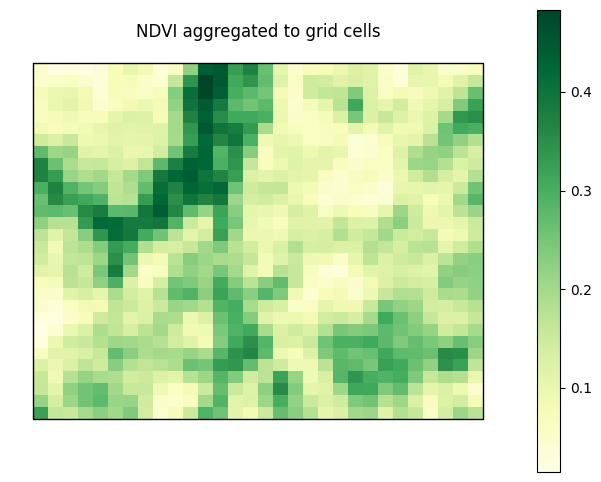

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ndvi_grid.plot(
    column="ndvi",
    ax=ax,
    cmap="YlGn",
    legend=True,
    edgecolor="none",
    missing_kwds={"color": "lightgray", "label": "No data"},
)
bbox_gdf.to_crs(ndvi_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("NDVI aggregated to grid cells")
ax.set_axis_off()
plt.show()

In [5]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
ndvi_grid.to_file(OUTPUT_PATH, driver="GeoJSON")
print(f"Saved NDVI grid to: {OUTPUT_PATH}")

Saved NDVI grid to: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/data/layers/ndvi_grid.geojson


## NDBI Extraction

In [ ]:
NDBI_OUTPUT_PATH = LAYERS_DIR / "ndbi_grid.geojson"

# Adjust date range and cloud cover as needed.
NDBI_DATE_RANGE = "2025-05-01/2025-09-30"
NDBI_MAX_CLOUD_COVER = 20.0
NDBI_MAX_ITEMS = 30

In [5]:
ndbi_extractor = NDBIExtractor(
    datetime_range=NDBI_DATE_RANGE,
    max_cloud_cover=NDBI_MAX_CLOUD_COVER,
    max_items=NDBI_MAX_ITEMS,
    grid_path=GRID_PATH,
)

ndbi_grid = ndbi_extractor.extract_for_grid(bbox)
ndbi_grid.head()

/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/ndbi_extractor.py:147: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_ndbi = intersections.groupby("id").apply(


,id,geometry,ndbi
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",-0.207903
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",-0.159759
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",-0.127417
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",-0.112085
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",-0.074170


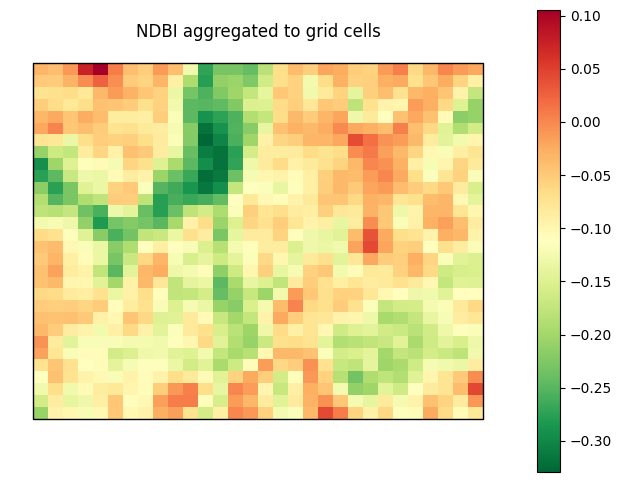

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
ndbi_grid.plot(
    column="ndbi",
    ax=ax,
    cmap="RdYlGn_r",
    legend=True,
    edgecolor="none",
    missing_kwds={"color": "lightgray", "label": "No data"},
)
bbox_gdf.to_crs(ndbi_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("NDBI aggregated to grid cells")
ax.set_axis_off()
plt.show()

In [7]:
NDBI_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
ndbi_grid.to_file(NDBI_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved NDBI grid to: {NDBI_OUTPUT_PATH}")

Saved NDBI grid to: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/data/layers/ndbi_grid.geojson


## NLCD Impervious Surface Extraction

In [ ]:
IMPERVIOUS_OUTPUT_PATH = LAYERS_DIR / "nlcd_impervious_grid.geojson"

# Annual NLCD supports years 1985-2024; use 2024 by default.
IMPERVIOUS_YEAR = 2024
IMPERVIOUS_REGION = "CU"
IMPERVIOUS_COLLECTION = 1
IMPERVIOUS_VERSION = 1

# Local NLCD raster path (.tif or .zip). Set to None to fetch remotely via AWS S3.
IMPERVIOUS_LOCAL_PATH = str(PROJECT_ROOT / "data" / "kriging_satellite" / "nlcd" / "Annual_NLCD_FctImp_2024_CU_C1V1.zip")

In [5]:
impervious_extractor = NLCDImperviousExtractor(
    year=IMPERVIOUS_YEAR,
    region=IMPERVIOUS_REGION,
    collection=IMPERVIOUS_COLLECTION,
    version=IMPERVIOUS_VERSION,
    local_raster_path=IMPERVIOUS_LOCAL_PATH,
    grid_path=GRID_PATH,
)

impervious_grid = impervious_extractor.extract_for_grid(bbox)
impervious_grid.head()

/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/nlcd_impervious_extractor.py:157: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_vals = intersections.groupby("id").apply(


,id,geometry,impervious
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",59.043725
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",74.126761
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",76.528328
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",77.903810
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",79.078385


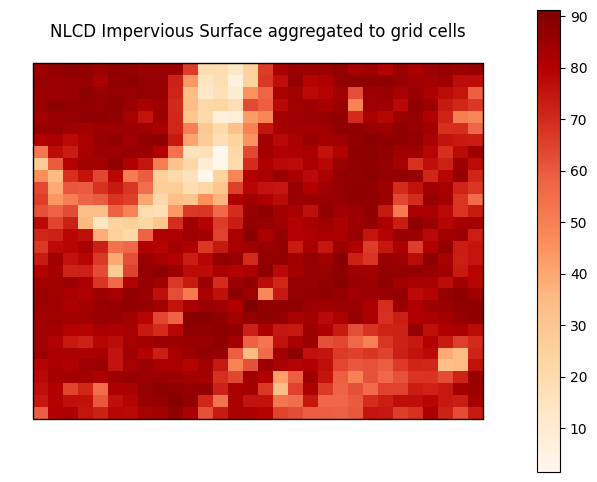

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
impervious_grid.plot(
    column="impervious",
    ax=ax,
    cmap="OrRd",
    legend=True,
    edgecolor="none",
    missing_kwds={"color": "lightgray", "label": "No data"},
)
bbox_gdf.to_crs(impervious_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("NLCD Impervious Surface aggregated to grid cells")
ax.set_axis_off()
plt.show()

In [7]:
IMPERVIOUS_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
impervious_grid.to_file(IMPERVIOUS_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved NLCD impervious grid to: {IMPERVIOUS_OUTPUT_PATH}")

Saved NLCD impervious grid to: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/data/layers/nlcd_impervious_grid.geojson


## TIGER Road Density Extraction

In [ ]:
ROAD_OUTPUT_PATH = LAYERS_DIR / "road_density_grid.geojson"

# Boston (Suffolk County, MA) defaults.
TIGER_YEAR = 2024
TIGER_STATE_FIPS = "25"
TIGER_COUNTY_FIPS = "025"

# Optional local TIGER roads file (.zip/.shp/.gpkg/.geojson).
TIGER_LOCAL_PATH = None

In [15]:
road_extractor = TIGERRoadDensityExtractor(
    year=TIGER_YEAR,
    state_fips=TIGER_STATE_FIPS,
    county_fips=TIGER_COUNTY_FIPS,
    local_roads_path=TIGER_LOCAL_PATH,
    grid_path=GRID_PATH,
)

road_grid = road_extractor.extract_for_grid(bbox)
road_grid.head()

,id,geometry,road_density_km_km2,major_road_density_km_km2
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",NaN,NaN
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",24.844960,NaN
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",37.069438,NaN
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",14.902990,NaN
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",17.275134,NaN


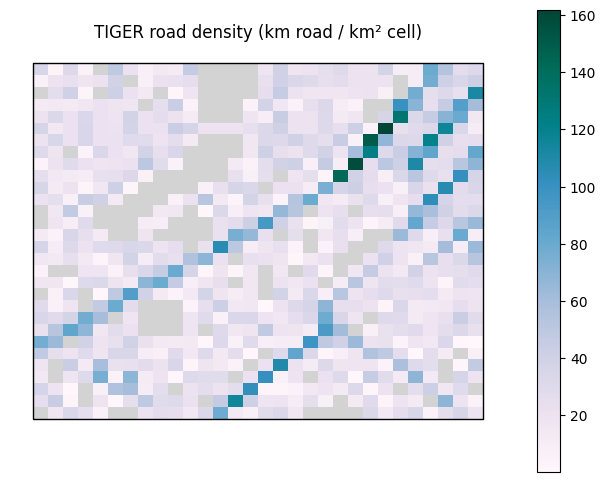

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
road_grid.plot(
    column="road_density_km_km2",
    ax=ax,
    cmap="PuBuGn",
    legend=True,
    edgecolor="none",
    missing_kwds={"color": "lightgray", "label": "No data"},
)
bbox_gdf.to_crs(road_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("TIGER road density (km road / km² cell)")
ax.set_axis_off()
plt.show()

In [17]:
ROAD_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
road_grid.to_file(ROAD_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved road density grid to: {ROAD_OUTPUT_PATH}")

Saved road density grid to: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/data/layers/road_density_grid.geojson


## EPA NEI Emissions Extraction

### Prepare NEI Input (One-Time)

In [ ]:
import requests

nei_dir = PROJECT_ROOT / "data" / "kriging_satellite" / "nei"
nei_dir.mkdir(parents=True, exist_ok=True)

# 2020 NEI point emissions summary zip (EPA official).
NEI_POINT_URL = "https://gaftp.epa.gov/air/nei/2020/data_summaries/2020nei_facility_process_byregions.zip"
NEI_POINT_ZIP_PATH = nei_dir / "2020nei_facility_process_byregions.zip"

if not NEI_POINT_ZIP_PATH.exists():
    print(f"Downloading: {NEI_POINT_URL}")
    response = requests.get(NEI_POINT_URL, timeout=300)
    response.raise_for_status()
    NEI_POINT_ZIP_PATH.write_bytes(response.content)
    print(f"Saved: {NEI_POINT_ZIP_PATH}")
else:
    print(f"Using existing file: {NEI_POINT_ZIP_PATH}")

In [ ]:
NEI_OUTPUT_PATH = LAYERS_DIR / "nei_emissions_grid.geojson"

# Default to downloaded EPA NEI point zip from the prep cell.
NEI_LOCAL_PATH = str(PROJECT_ROOT / "data" / "kriging_satellite" / "nei" / "2020nei_facility_process_byregions.zip")

# Column names in EPA 2020 facility/process-by-region files.
NEI_EMISSION_COLUMN = "total emissions"
NEI_SOURCE_TYPE_COLUMN = "facility source type"
NEI_LONGITUDE_COLUMN = "site longitude"
NEI_LATITUDE_COLUMN = "site latitude"

In [6]:
from pathlib import Path

if not NEI_LOCAL_PATH:
    raise ValueError("Set NEI_LOCAL_PATH to your local NEI file before running this cell.")
if not Path(NEI_LOCAL_PATH).exists():
    raise FileNotFoundError(f"NEI file not found: {NEI_LOCAL_PATH}")

nei_extractor = NEIEmissionsExtractor(
    local_data_path=NEI_LOCAL_PATH,
    emission_column=NEI_EMISSION_COLUMN,
    source_type_column=NEI_SOURCE_TYPE_COLUMN,
    longitude_column=NEI_LONGITUDE_COLUMN,
    latitude_column=NEI_LATITUDE_COLUMN,
    grid_path=GRID_PATH,
)

nei_grid = nei_extractor.extract_for_grid(bbox)
nei_grid.head()

,id,geometry,emissions_tpy,emissions_point_tpy,emissions_area_tpy
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",NaN,NaN,NaN
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",NaN,NaN,NaN
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",NaN,NaN,NaN
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",NaN,NaN,NaN
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",NaN,NaN,NaN


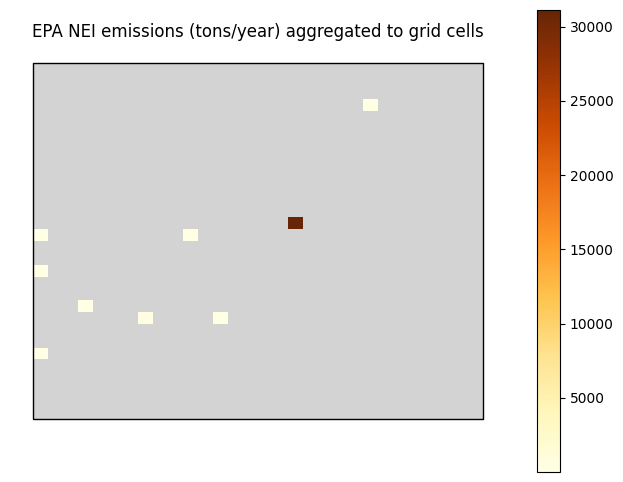

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
nei_grid.plot(
    column="emissions_tpy",
    ax=ax,
    cmap="YlOrBr",
    legend=True,
    edgecolor="none",
    missing_kwds={"color": "lightgray", "label": "No data"},
)

bbox_gdf.to_crs(nei_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("EPA NEI emissions (tons/year) aggregated to grid cells")
ax.set_axis_off()
plt.show()

In [8]:
NEI_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
nei_grid.to_file(NEI_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved NEI emissions grid to: {NEI_OUTPUT_PATH}")

Saved NEI emissions grid to: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/data/layers/nei_emissions_grid.geojson


## Census Population Density Extraction

### Prepare Block-Group Population Input (One-Time)

In [ ]:
import zipfile
import requests
import pandas as pd
import geopandas as gpd

# Local geometry zip path for MA block groups.
bg_zip_path = PROJECT_ROOT / "data" / "kriging_satellite" / "census" / "tl_2025_25_bg.zip"
bg_zip_url = "https://www2.census.gov/geo/tiger/TIGER2025/BG/tl_2025_25_bg.zip"
if not bg_zip_path.exists():
    bg_zip_path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading: {bg_zip_url}")
    response = requests.get(bg_zip_url, timeout=120)
    response.raise_for_status()
    bg_zip_path.write_bytes(response.content)
    print(f"Saved: {bg_zip_path}")

# 1) Pull ACS total population by block group (B01003_001E)
url = "https://api.census.gov/data/2023/acs/acs5"
params = {
    "get": "B01003_001E",
    "for": "block group:*",
    "in": "state:25 county:* tract:*",
}
rows = requests.get(url, params=params, timeout=60).json()
pop_df = pd.DataFrame(rows[1:], columns=rows[0])
pop_df["GEOID"] = pop_df["state"] + pop_df["county"] + pop_df["tract"] + pop_df["block group"]
pop_df["population"] = pd.to_numeric(pop_df["B01003_001E"], errors="coerce")
pop_df = pop_df[["GEOID", "population"]]

# 2) Join to block-group geometry
bg_extract_dir = bg_zip_path.parent / "tl_2025_25_bg_unzipped"
if not bg_extract_dir.exists():
    with zipfile.ZipFile(bg_zip_path) as zf:
        zf.extractall(bg_extract_dir)

bg_gdf = gpd.read_file(bg_extract_dir)
bg_gdf = bg_gdf.merge(pop_df, on="GEOID", how="left")

# 3) Save to GeoPackage for reuse
bg_gpkg_path = PROJECT_ROOT / "data" / "kriging_satellite" / "census" / "census_population_bg.gpkg"
bg_gdf.to_file(bg_gpkg_path, driver="GPKG")
print(f"Saved block-group population to: {bg_gpkg_path}")

In [ ]:
POP_OUTPUT_PATH = LAYERS_DIR / "population_density_grid.geojson"

# Default to the prepared block-group file from the previous cell.
POP_LOCAL_PATH = str(PROJECT_ROOT / "data" / "kriging_satellite" / "census" / "census_population_bg.gpkg")
POPULATION_COLUMN = "population"

In [11]:
if not POP_LOCAL_PATH:
    raise ValueError("Set POP_LOCAL_PATH to your local Census file before running this cell.")

population_extractor = CensusPopulationDensityExtractor(
    local_data_path=POP_LOCAL_PATH,
    population_column=POPULATION_COLUMN,
    grid_path=GRID_PATH,
)

population_grid = population_extractor.extract_for_grid(bbox)
population_grid.head()

,id,geometry,population,population_density_km2
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",301.279208,94806.493276
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",286.304695,90094.319191
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",107.636015,33870.886499
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",117.593836,37004.413783
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",192.642235,60620.636728


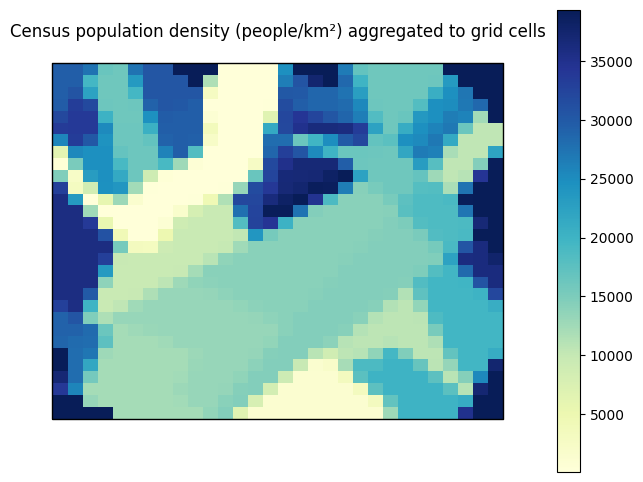

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
#clip the population densities for visualization
min_percentile = 5
max_percentile = 95
population_grid["population_density_km2_clipped"] = population_grid["population_density_km2"].clip(
    lower=population_grid["population_density_km2"].quantile(min_percentile / 100),
    upper=population_grid["population_density_km2"].quantile(max_percentile / 100),
)

population_grid.plot(
    column="population_density_km2_clipped",
    ax=ax,
    cmap="YlGnBu",
    legend=True,
    edgecolor="none",
    missing_kwds={"color": "lightgray", "label": "No data"},
)


bbox_gdf.to_crs(population_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Census population density (people/km²) aggregated to grid cells")
ax.set_axis_off()
plt.show()

In [13]:
POP_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
population_grid.to_file(POP_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved population density grid to: {POP_OUTPUT_PATH}")

Saved population density grid to: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation_Std_Layers/data/layers/population_density_grid.geojson
